In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Set random seed for reproducibility
torch.manual_seed(42)
device = torch.device('cpu')

# Define the Baseline CNN Architecture
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        # Two convolution layers
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5, stride=1, padding=2) # Output: 16x28x28
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Output: 16x14x14
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=2) # Output: 32x14x14
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) # Output: 32x7x7
        # Two fully connected layers
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool1(x)
        x = self.relu(self.conv2(x))
        x = self.pool2(x)
        x = x.view(x.size(0), -1) # Flatten
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Load MNIST Dataset
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# Initialize model, loss, and optimizer
model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the Baseline CNN
print("Training baseline CNN (2 epochs)... ", end="")
epochs = 2
model.train()
for epoch in range(epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
print("done.")

# Evaluate Clean Test Accuracy
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

clean_accuracy = (correct / total) * 100
print(f"Clean test accuracy : {clean_accuracy:.1f} %")

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 597kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.43MB/s]


Training baseline CNN (2 epochs)... done.
Clean test accuracy : 98.7 %


In [ ]:
def fgsm_attack(image, epsilon, data_grad):
    """
    Generates adversarial examples using Fast Gradient Sign Method (FGSM).
    image: Original clean images
    epsilon: Perturbation amount
    data_grad: Gradient of the loss with respect to the input image
    """
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()

    # Create the perturbed image by adjusting each pixel of the input image
    perturbed_image = image + epsilon * sign_data_grad

    # Adding clipping to maintain the [0, 1] range of pixel values
    perturbed_image = torch.clamp(perturbed_image, 0, 1)

    # Return the perturbed image
    return perturbed_image

In [ ]:
import torch.nn.functional as F

def test_fgsm(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    for data, target in test_loader:
        data, target = data.to(device), target.to(device)

        # Set requires_grad attribute on input tensor for generating adversarial images
        data.requires_grad = True

        # Forward pass
        output = model(data)
        loss = F.cross_entropy(output, target)

        # Zero all existing gradients
        model.zero_grad()

        # Backward pass to calculate gradients
        loss.backward()

        # Collect the gradient of the input data
        data_grad = data.grad.data

        # Call FGSM Attack
        perturbed_data = fgsm_attack(data, epsilon, data_grad)

        # Re-classify the perturbed image
        output_perturbed = model(perturbed_data)
        _, final_pred = torch.max(output_perturbed.data, 1)

        total += target.size(0)
        correct += (final_pred == target).sum().item()

    acc = (correct / total) * 100
    return acc

# Run evaluation over the specified epsilons
epsilons = [0.00, 0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = []

print("Evaluating FGSM attack...")
for eps in epsilons:
    acc = test_fgsm(model, device, test_loader, eps)
    fgsm_accuracies.append(acc)
    print(f"Epsilon: {eps:.2f}\tTest Accuracy = {acc:.1f} %")

Evaluating FGSM attack...
Epsilon: 0.00	Test Accuracy = 98.7 %
Epsilon: 0.05	Test Accuracy = 93.1 %
Epsilon: 0.10	Test Accuracy = 75.2 %
Epsilon: 0.20	Test Accuracy = 24.2 %
Epsilon: 0.30	Test Accuracy = 5.6 %


In [ ]:
def pgd_attack(model, images, labels, epsilon, alpha=None, num_iter=10, device='cpu'):
    if alpha is None:
        alpha = epsilon / 4.0

    # If epsilon is 0, return the clean images directly
    if epsilon == 0:
        return images.clone().detach()

    # Random initialization within epsilon-L_infinity ball
    perturbed_images = images.clone().detach() + torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_images = torch.clamp(perturbed_images, 0.0, 1.0) # Project back into [0, 1] bounds

    for i in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = F.cross_entropy(outputs, labels)

        model.zero_grad()
        loss.backward()

        # Gradient ascent step
        grad = perturbed_images.grad.data
        perturbed_images = perturbed_images.detach() + alpha * grad.sign()

        # Projection step back to L_infinity ball around original images
        eta = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + eta, min=0.0, max=1.0).detach()

    return perturbed_images

def test_pgd(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    for data, target in test_loader:
        data, target = data.to(device), target.to(device)

        # Call PGD Attack
        perturbed_data = pgd_attack(model, data, target, epsilon, device=device)

        # Re-classify the perturbed image
        output_perturbed = model(perturbed_data)
        _, final_pred = torch.max(output_perturbed.data, 1)

        total += target.size(0)
        correct += (final_pred == target).sum().item()

    acc = (correct / total) * 100
    return acc

# Run evaluation over the specified epsilons for PGD
pgd_accuracies = []

print("Evaluating PGD attack...")
for eps in epsilons:
    acc = test_pgd(model, device, test_loader, eps)
    pgd_accuracies.append(acc)
    print(f"Epsilon: {eps:.2f}\tTest Accuracy = {acc:.1f} %")

Evaluating PGD attack...
Epsilon: 0.00	Test Accuracy = 98.7 %
Epsilon: 0.05	Test Accuracy = 91.0 %
Epsilon: 0.10	Test Accuracy = 56.4 %
Epsilon: 0.20	Test Accuracy = 1.0 %
Epsilon: 0.30	Test Accuracy = 0.0 %


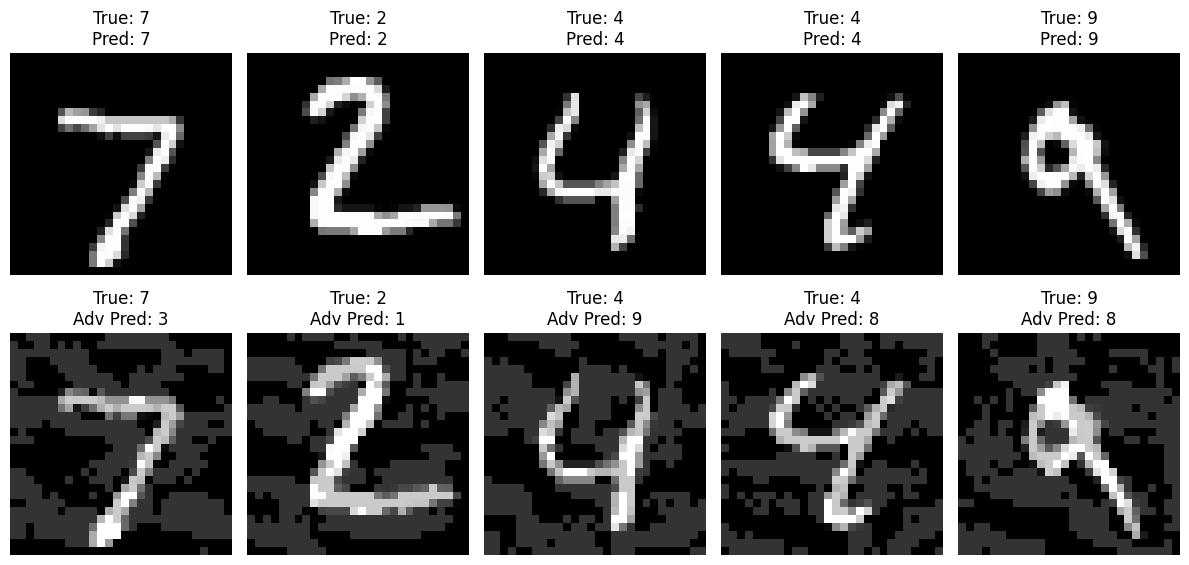

In [ ]:
import matplotlib.pyplot as plt
import random

# Put model in eval mode
model.eval()

# Find 5 random examples to attack
examples_to_plot = []

for data, target in test_loader:
    data, target = data.to(device), target.to(device)
    data.requires_grad = True

    output = model(data)
    loss = F.cross_entropy(output, target)
    model.zero_grad()
    loss.backward()

    data_grad = data.grad.data
    perturbed_data = fgsm_attack(data, 0.20, data_grad)

    output_perturbed = model(perturbed_data)
    _, preds_clean = torch.max(output.data, 1)
    _, preds_adv = torch.max(output_perturbed.data, 1)

    # Pick a few instances where the prediction changes
    for idx in range(data.size(0)):
        if preds_clean[idx] == target[idx] and preds_adv[idx] != target[idx]:
            examples_to_plot.append({
                'clean': data[idx].cpu().detach().squeeze().numpy(),
                'adv': perturbed_data[idx].cpu().detach().squeeze().numpy(),
                'label': target[idx].item(),
                'pred_clean': preds_clean[idx].item(),
                'pred_adv': preds_adv[idx].item()
            })
        if len(examples_to_plot) >= 5:
            break
    if len(examples_to_plot) >= 5:
        break

# Fallback to any images if not enough misclassified are found immediately
if len(examples_to_plot) < 5:
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        data.requires_grad = True
        output = model(data)
        loss = F.cross_entropy(output, target)
        model.zero_grad()
        loss.backward()
        data_grad = data.grad.data
        perturbed_data = fgsm_attack(data, 0.20, data_grad)
        output_perturbed = model(perturbed_data)
        _, preds_clean = torch.max(output.data, 1)
        _, preds_adv = torch.max(output_perturbed.data, 1)
        for idx in range(data.size(0)):
            examples_to_plot.append({
                'clean': data[idx].cpu().detach().squeeze().numpy(),
                'adv': perturbed_data[idx].cpu().detach().squeeze().numpy(),
                'label': target[idx].item(),
                'pred_clean': preds_clean[idx].item(),
                'pred_adv': preds_adv[idx].item()
            })
            if len(examples_to_plot) >= 5:
                break
        if len(examples_to_plot) >= 5:
            break

# Plot the clean vs adversarial examples
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for col in range(5):
    example = examples_to_plot[col]

    # Clean display
    axes[0, col].imshow(example['clean'], cmap='gray')
    axes[0, col].set_title(f"True: {example['label']}\nPred: {example['pred_clean']}")
    axes[0, col].axis('off')

    # Adversarial display
    axes[1, col].imshow(example['adv'], cmap='gray')
    axes[1, col].set_title(f"True: {example['label']}\nAdv Pred: {example['pred_adv']}")
    axes[1, col].axis('off')

axes[0, 0].set_ylabel("Clean", size='large')
axes[1, 0].set_ylabel("Adversarial (eps=0.20)", size='large')

plt.tight_layout()
plt.savefig('clean_vs_adversarial.png')
plt.show()

In [ ]:
import copy

# Create a deep copy of the baseline model for adversarial training
adv_trained_model = copy.deepcopy(model)
adv_trained_model.to(device)

# Re-initialize optimizer for the new model
adv_optimizer = optim.Adam(adv_trained_model.parameters(), lr=0.001)
adv_trained_model.train()

print("Adversarial training (2 epochs with 50:50 mix)... ")
for epoch in range(2):
    running_loss = 0.0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)

        # Split batch into two halves: 50% clean, 50% adversarial
        batch_size = images.size(0)
        half_batch = batch_size // 2

        clean_images = images[:half_batch]
        clean_labels = labels[:half_batch]

        adv_images_src = images[half_batch:]
        adv_labels_src = labels[half_batch:]

        # Generate FGSM perturbations for the adversarial half
        adv_images_src.requires_grad = True
        outputs_src = adv_trained_model(adv_images_src)
        loss_src = criterion(outputs_src, adv_labels_src)

        adv_trained_model.zero_grad()
        loss_src.backward()

        data_grad = adv_images_src.grad.data
        perturbed_images = fgsm_attack(adv_images_src, 0.20, data_grad)

        # Combine the clean and perturbed adversarial images into a single training batch
        mixed_images = torch.cat([clean_images, perturbed_images.detach()], dim=0)
        mixed_labels = torch.cat([clean_labels, adv_labels_src], dim=0)

        # Perform standard training update step
        adv_optimizer.zero_grad()
        outputs_mixed = adv_trained_model(mixed_images)
        loss_mixed = criterion(outputs_mixed, mixed_labels)
        loss_mixed.backward()
        adv_optimizer.step()

        running_loss += loss_mixed.item()

    print(f"Epoch {epoch + 1}/2 complete. Loss: {running_loss / len(train_loader):.4f}")

print("Adversarial training completed.")

# Re-evaluate the robust model
adv_trained_model.eval()

print("Evaluating Adversarially Trained Model...")
clean_acc_adv_model = test_fgsm(adv_trained_model, device, test_loader, epsilon=0.0)
fgsm_acc_adv_model = test_fgsm(adv_trained_model, device, test_loader, epsilon=0.20)
pgd_acc_adv_model = test_pgd(adv_trained_model, device, test_loader, epsilon=0.20)

print(f"--- Adversarially Trained Model Metrics (Epsilon = 0.20) ---")
print(f"Clean accuracy: {clean_acc_adv_model:.1f} %")
print(f"FGSM robustness: {fgsm_acc_adv_model:.1f} %")
print(f"PGD robustness: {pgd_acc_adv_model:.1f} %")

Adversarial training (2 epochs with 50:50 mix)... 
Epoch 1/2 complete. Loss: 0.3649
Epoch 2/2 complete. Loss: 0.2172
Adversarial training completed.
Evaluating Adversarially Trained Model...
--- Adversarially Trained Model Metrics (Epsilon = 0.20) ---
Clean accuracy: 98.9 %
FGSM robustness: 87.4 %
PGD robustness: 43.1 %


Evaluating Adversarially Trained model over all epsilons...
Epsilon: 0.00 | FGSM Acc: 98.9 % | PGD Acc: 98.9 %
Epsilon: 0.05 | FGSM Acc: 97.3 % | PGD Acc: 96.2 %
Epsilon: 0.10 | FGSM Acc: 95.1 % | PGD Acc: 89.5 %
Epsilon: 0.20 | FGSM Acc: 87.4 % | PGD Acc: 43.0 %
Epsilon: 0.30 | FGSM Acc: 65.0 % | PGD Acc: 0.7 %


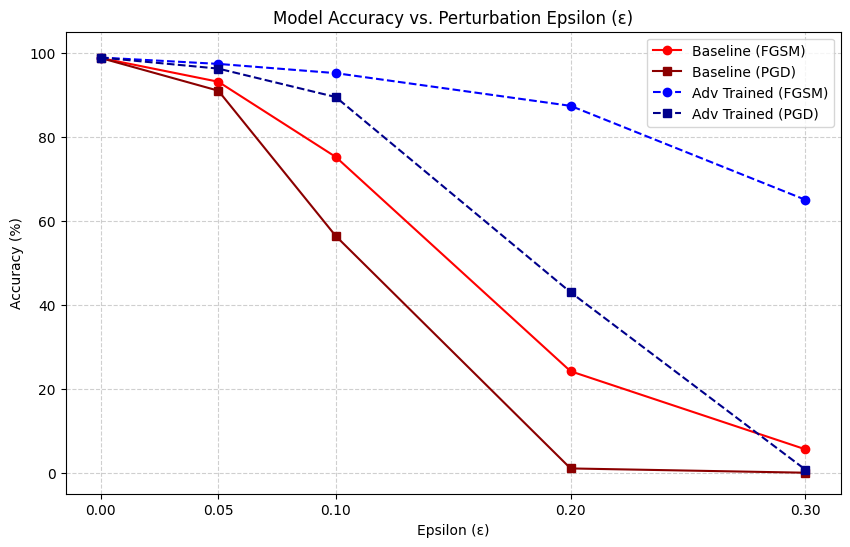

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Evaluate the Adversarially Trained model over the range of epsilons for plotting
print("Evaluating Adversarially Trained model over all epsilons...")
adv_fgsm_accuracies = []
adv_pgd_accuracies = []

for eps in epsilons:
    adv_fgsm_acc = test_fgsm(adv_trained_model, device, test_loader, eps)
    adv_pgd_acc = test_pgd(adv_trained_model, device, test_loader, eps)
    adv_fgsm_accuracies.append(adv_fgsm_acc)
    adv_pgd_accuracies.append(adv_pgd_acc)
    print(f"Epsilon: {eps:.2f} | FGSM Acc: {adv_fgsm_acc:.1f} % | PGD Acc: {adv_pgd_acc:.1f} %")

# Plotting Accuracy vs Epsilon
plt.figure(figsize=(10, 6))
plt.plot(epsilons, fgsm_accuracies, 'o-', label='Baseline (FGSM)', color='red')
plt.plot(epsilons, pgd_accuracies, 's-', label='Baseline (PGD)', color='darkred')
plt.plot(epsilons, adv_fgsm_accuracies, 'o--', label='Adv Trained (FGSM)', color='blue')
plt.plot(epsilons, adv_pgd_accuracies, 's--', label='Adv Trained (PGD)', color='darkblue')

plt.title('Model Accuracy vs. Perturbation Epsilon (ε)')
plt.xlabel('Epsilon (ε)')
plt.ylabel('Accuracy (%)')
plt.xticks(epsilons)
plt.ylim(-5, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Save the plot as requested in Task 6
plt.savefig('accuracy_vs_epsilon.png')
plt.show()


In [11]:
# Print final comparative table as requested
print("Expected Output — Part A: Baseline Model under Attack")
print(f"Clean test accuracy : {clean_accuracy:.1f} %\n")
print("EPSILON    FGSM_ACC    PGD_ACC")
print("-------------------------------")
for i, eps in enumerate(epsilons):
    print(f" {eps:.2f}       {fgsm_accuracies[i]:.1f} %      {pgd_accuracies[i]:.1f} %")
print("-------------------------------\n")

print("Expected Output — Part B: Adversarial Training (Defence)")
print("MODEL              CLEAN    FGSM(0.20)   PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline           {clean_accuracy:.1f} %     {fgsm_accuracies[3]:.1f} %       {pgd_accuracies[3]:.1f} % ")
print(f"Adversarially      {clean_acc_adv_model:.1f} %     {fgsm_acc_adv_model:.1f} %      {pgd_acc_adv_model:.1f} %")
print("trained")
print("----------------------------------------------------")
print(f"Clean accuracy change : {clean_acc_adv_model - clean_accuracy:+.1f} %")
print(f"FGSM robustness gain  : {fgsm_acc_adv_model - fgsm_accuracies[3]:+.1f} %    PGD gain : {pgd_acc_adv_model - pgd_accuracies[3]:+.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")


Expected Output — Part A: Baseline Model under Attack
Clean test accuracy : 98.7 %

EPSILON    FGSM_ACC    PGD_ACC
-------------------------------
 0.00       98.7 %      98.7 %
 0.05       93.1 %      91.0 %
 0.10       75.2 %      56.4 %
 0.20       24.2 %      1.0 %
 0.30       5.6 %      0.0 %
-------------------------------

Expected Output — Part B: Adversarial Training (Defence)
MODEL              CLEAN    FGSM(0.20)   PGD(0.20)
----------------------------------------------------
Baseline           98.7 %     24.2 %       1.0 % 
Adversarially      98.9 %     87.4 %      43.1 %
trained
----------------------------------------------------
Clean accuracy change : +0.1 %
FGSM robustness gain  : +63.2 %    PGD gain : +42.1 %
Plot saved : accuracy_vs_epsilon.png
